# Tests T17-T19 of the too-low LI-7500 nights: comparison of the results

**notebook version**: `1` (11 Nov 2026)

## ℹ️ About this notebook

Compares the LI-7500 CO2 flux of the product (rerun of 10 Nov 2026, daytime heat scale 0.6 before
2008) with three tests of its nights, which lie 50 to 120 gC m⁻² per year below the LI-7200 years
in every period (plan section 5, step 4). All runs use the same input (`IRGA75/01` version 3):

| Run | Notebook | Change against the product |
|---|---|---|
| Product | `IRGA75/05` | none |
| T17 | `IRGA75/T17_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETWN_2004-2017` | Lloyd-Taylor fill of the wet night gaps raised by its offset to the LI-7200 in the parallel period |
| T18 | `IRGA75/T18_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETALL_2004-2017` | every night fill raised by the offset of its fill flag |
| T19 | `IRGA75/T19_05_FPPC_IRGA75_NEE_OPCO_COLDWETSCREEN_2004-2017` | measured cold nights (below 2 °C) with a wet window or an overcast sky removed before gap-filling |

The offsets of T17 and T18 are fitted in the parallel period, so the parallel period is closed by
construction; their effect on 2004-2015 is what the tests measure. For the LI-7500 the product fill
`_gfXGWN` is compared, for the LI-7200 the plain XGBoost fill `_gfXG`, as in the product. A run whose
output file is missing (not run, or failed) is left out and reported.

## ⚙️ Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
STAGE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN'

RUNS = {
    'product': ('IRGA75', STAGE / 'IRGA75' / '05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet'),
    'T17 wet-night offset': ('IRGA75', STAGE / 'IRGA75' / 'T17_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETWN_2004-2017.parquet'),
    'T18 night offset': ('IRGA75', STAGE / 'IRGA75' / 'T18_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETALL_2004-2017.parquet'),
    'T19 cold wet screen': ('IRGA75', STAGE / 'IRGA75' / 'T19_05_FPPC_IRGA75_NEE_OPCO_COLDWETSCREEN_2004-2017.parquet'),
    'IRGA72 product': ('IRGA72', STAGE / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet'),
}
TEST_RUNS = ['product', 'T17 wet-night offset', 'T18 night offset', 'T19 cold wet screen']

FILL = {'IRGA75': '_gfXGWN', 'IRGA72': '_gfXG'}
SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']
YEARS = {'IRGA75': range(2004, 2018), 'IRGA72': range(2016, 2026)}
PERIODS = {'2004-2006': (2004, 2006), '2007-2009': (2007, 2009), '2010-2015': (2010, 2015),
           '2016-2017': (2016, 2017), '2005-2009': (2005, 2009)}
REF_YEARS = (2016, 2025)
PARALLEL = ('2016-01-11', '2017-12-12')
DT_FIRST_YEAR = 2006
GROWING = (5, 6, 7, 8, 9, 10)  # May-Oct

# Etzold et al. (2011), mean annual NEE 2005-2009 and its range, as declared in
# 90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.
ETZOLD_YEARS = (2005, 2009)
ETZOLD_MEAN = -415
ETZOLD_RANGE = (-662, -366)

UMOL_TO_GC = 12.011e-6 * 1800

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)


def tabcap(text, width=110):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-11 17:56:49


## 📂 Load data

In [3]:
def columns(analyser):
    fill = FILL[analyser]
    cols = [f'NEE_L3.1_L3.3_{s}_QCF{fill}' for s in SCENARIOS] + ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS',
            'NEE_L3.1_L3.3_CUT_50_QCF', 'DAYTIME', 'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50',
            'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50']
    cols.append(f'FLAG_NEE_L3.1_L3.3_CUT_50_QCF{fill}_ISFILLED')
    return cols


DATA, MISSING = {}, []
for label, (analyser, path) in RUNS.items():
    if not path.is_file():
        MISSING.append(label)
        continue
    df = pd.read_parquet(path, columns=columns(analyser))
    df.index = pd.DatetimeIndex(df.index)
    # Short names: NEE per scenario with the product fill, and the rest as they are.
    df = df.rename(columns={f'NEE_L3.1_L3.3_{s}_QCF{FILL[analyser]}': s for s in SCENARIOS}
                   | {f'FLAG_NEE_L3.1_L3.3_CUT_50_QCF{FILL[analyser]}_ISFILLED': 'FILLFLAG'})
    assert not df.index.duplicated().any(), f"{label}: duplicate timestamps"
    DATA[label] = df
    print(f"{label}: {path.name}, modified {datetime.fromtimestamp(path.stat().st_mtime):%Y-%m-%d %H:%M}")
print(f"\nmissing (not run or failed): {MISSING if MISSING else 'none'}")
assert 'product' in DATA and 'IRGA72 product' in DATA, "a product run is missing"


def annual(label, col='CUT_50', mask=None):
    """Annual sums (gC m-2) of one column over the complete years of the run's analyser."""
    df = DATA[label]
    s = df[col] if mask is None else df[col].where(mask(df), 0.0)
    years = YEARS[RUNS[label][0]]
    return (s.groupby(df.index.year).sum() * UMOL_TO_GC).reindex(years)


def period_mean(series, period):
    lo, hi = PERIODS[period] if isinstance(period, str) else period
    return series.loc[lo:hi].mean()


REF = annual('IRGA72 product')
REF_MEAN = period_mean(REF, REF_YEARS)
print(f"LI-7200 mean annual NEE {REF_YEARS[0]}-{REF_YEARS[1]} (CUT_50): {REF_MEAN:.0f} gC m-2")

product: 05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet, modified 2026-11-10 19:34


T17 wet-night offset: T17_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETWN_2004-2017.parquet, modified 2026-11-11 16:02
T18 night offset: T18_05_FPPC_IRGA75_NEE_OPCO_NIGHTOFFSETALL_2004-2017.parquet, modified 2026-11-11 17:01
T19 cold wet screen: T19_05_FPPC_IRGA75_NEE_OPCO_COLDWETSCREEN_2004-2017.parquet, modified 2026-11-11 17:56


IRGA72 product: 05_FPPC_IRGA72_NEE_2016-2026.09.parquet, modified 2026-11-04 15:46

missing (not run or failed): none
LI-7200 mean annual NEE 2016-2025 (CUT_50): -23 gC m-2


## 1. Annual sums

### 📋 Table: annual NEE of the LI-7500 per run

In [4]:
ann = pd.DataFrame({l: annual(l) for l in TEST_RUNS if l in DATA})
ann.index.name = 'year'
tabcap("annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 per run")
display(ann.round(0))

Table - annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 per run



,product,T17 wet-night offset,T18 night offset,T19 cold wet screen
year,,,,
2004,-18.0,77.0,186.0,-44.0
2005,54.0,153.0,253.0,87.0
2006,271.0,376.0,466.0,284.0
2007,-41.0,55.0,145.0,-12.0
2008,126.0,225.0,314.0,200.0
2009,99.0,195.0,295.0,122.0
2010,32.0,145.0,230.0,73.0
2011,8.0,115.0,202.0,52.0
2012,-32.0,88.0,174.0,-19.0


### 📋 Table: period means against the LI-7200 years and Etzold et al. (2011)

In [5]:
_rows = {}
for l in ann.columns:
    s = ann[l]
    _r = {p: period_mean(s, p) for p in PERIODS}
    _r.update({f"{p} minus LI-7200": period_mean(s, p) - REF_MEAN
               for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017')})
    _r['2005-2009 minus Etzold et al.'] = period_mean(s, ETZOLD_YEARS) - ETZOLD_MEAN
    _rows[l] = _r
periods = pd.DataFrame(_rows).T
tabcap(f"mean annual NEE (gC m-2) per period and run, its difference to the LI-7200 mean of "
       f"{REF_YEARS[0]}-{REF_YEARS[1]} ({REF_MEAN:.0f}) and to Etzold et al. (2011) for 2005-2009 "
       f"({ETZOLD_MEAN}, range {ETZOLD_RANGE[0]} to {ETZOLD_RANGE[1]})")
display(periods.round(0))

Table - mean annual NEE (gC m-2) per period and run, its difference to the LI-7200 mean of 2016-2025 (-23) and
to Etzold et al. (2011) for 2005-2009 (-415, range -662 to -366)



,2004-2006,2007-2009,2010-2015,2016-2017,2005-2009,2004-2006 minus LI-7200,2007-2009 minus LI-7200,2010-2015 minus LI-7200,2016-2017 minus LI-7200,2005-2009 minus Etzold et al.
product,102.0,62.0,-6.0,-73.0,102.0,125.0,84.0,17.0,-50.0,517.0
T17 wet-night offset,202.0,159.0,101.0,31.0,201.0,225.0,181.0,124.0,54.0,616.0
T18 night offset,301.0,251.0,190.0,126.0,295.0,324.0,274.0,213.0,149.0,710.0
T19 cold wet screen,109.0,103.0,18.0,-32.0,136.0,132.0,126.0,41.0,-10.0,551.0


## 2. Where the gap sits

### 📋 Table: gap to the LI-7200 by season, day and night

In [6]:
PARTS = {'May-Oct day': lambda d: d.index.month.isin(GROWING) & (d['DAYTIME'] == 1),
         'May-Oct night': lambda d: d.index.month.isin(GROWING) & (d['DAYTIME'] != 1),
         'Nov-Apr day': lambda d: ~d.index.month.isin(GROWING) & (d['DAYTIME'] == 1),
         'Nov-Apr night': lambda d: ~d.index.month.isin(GROWING) & (d['DAYTIME'] != 1)}
_ref = {k: period_mean(annual('IRGA72 product', mask=f), REF_YEARS) for k, f in PARTS.items()}
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    _a = {k: annual(l, mask=f) for k, f in PARTS.items()}
    for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017'):
        _r = {k: period_mean(v, p) - _ref[k] for k, v in _a.items()}
        _r['total'] = sum(_r.values())
        _rows[(l, p)] = _r
gap = pd.DataFrame(_rows).T
tabcap(f"LI-7500 period mean minus the LI-7200 mean of {REF_YEARS[0]}-{REF_YEARS[1]} (gC m-2 per year, "
       f"CUT_50, product fill), by season (May-Oct, Nov-Apr) and by day and night (DAYTIME flag). LI-7200 "
       f"reference: " + ", ".join(f"{k} {v:.0f}" for k, v in _ref.items()))
display(gap.round(0))

Table - LI-7500 period mean minus the LI-7200 mean of 2016-2025 (gC m-2 per year, CUT_50, product fill), by
season (May-Oct, Nov-Apr) and by day and night (DAYTIME flag). LI-7200 reference: May-Oct day -894, May-Oct
night 472, Nov-Apr day 20, Nov-Apr night 379



May-Oct day  May-Oct night  Nov-Apr day  Nov-Apr night  total
product              2004-2006        222.0          -49.0         -4.0          -44.0  125.0
                     2007-2009        104.0          -61.0         57.0          -16.0   84.0
                     2010-2015         67.0          -66.0         17.0           -2.0   17.0
                     2016-2017         65.0          -74.0          1.0          -43.0  -50.0
T17 wet-night offset 2004-2006        222.0          -10.0         -4.0           16.0  225.0
                     2007-2009        104.0          -26.0         57.0           47.0  181.0
                     2010-2015         67.0          -27.0         17.0           67.0  124.0
                     2016-2017         65.0          -43.0          1.0           31.0   54.0
T18 night offset     2004-2006        222.0           33.0         -4.0           73.0  324.0
                     2007-2009        104.0           19.0         57.0           94.0  274.0
                     2010-2015         67.0           17.0         17.0          111.0  213.0
                     2016-2017         65.0            8.0          1.0           74.0  149.0
T19 cold wet screen  2004-2006        221.0          -48.0         -7.0          -35.0  132.0
                     2007-2009        105.0          -59.0         68.0           11.0  126.0
                     2010-2015         62.0          -65.0         21.0           22.0   41.0
                     2016-2017         67.0          -73.0          1.0           -5.0  -10.0

### 📋 Table: partitioning per period

In [7]:
_cols = ('GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50', 'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50')
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017'):
        lo, hi = PERIODS[p]
        _rows[(l, p)] = {c: period_mean(annual(l, c), (max(lo, DT_FIRST_YEAR) if '_DT_' in c else lo, hi))
                         for c in _cols}
_rows[('LI-7200', f"{REF_YEARS[0]}-{REF_YEARS[1]}")] = {c: period_mean(annual('IRGA72 product', c), REF_YEARS)
                                                       for c in _cols}
part = pd.DataFrame(_rows).T
tabcap(f"mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period "
       f"and run; the daytime method from {DT_FIRST_YEAR}")
display(part.round(0))

Table - mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period and
run; the daytime method from 2006



GPP_NT_OF_CUT_50  RECO_NT_OF_CUT_50  GPP_DT_OF_CUT_50  RECO_DT_OF_CUT_50
product              2004-2006            1396.0             1498.0            1339.0             1704.0
                     2007-2009            1590.0             1651.0            1577.0             1888.0
                     2010-2015            1619.0             1612.0            1575.0             1786.0
                     2016-2017            1679.0             1606.0            1804.0             1856.0
T17 wet-night offset 2004-2006            1297.0             1498.0            1339.0             1704.0
                     2007-2009            1493.0             1651.0            1577.0             1888.0
                     2010-2015            1511.0             1612.0            1575.0             1786.0
                     2016-2017            1575.0             1606.0            1804.0             1856.0
T18 night offset     2004-2006            1197.0             1498.0            1339.0             1704.0
                     2007-2009            1400.0             1651.0            1577.0             1888.0
                     2010-2015            1422.0             1612.0            1575.0             1786.0
                     2016-2017            1480.0             1606.0            1804.0             1856.0
T19 cold wet screen  2004-2006            1397.0             1506.0            1331.0             1697.0
                     2007-2009            1581.0             1684.0            1573.0             1842.0
                     2010-2015            1642.0             1660.0            1570.0             1757.0
                     2016-2017            1677.0             1645.0            1800.0             1854.0
LI-7200              2016-2025            1885.0             1863.0            2071.0             2241.0

### 📋 Table: LI-7500 minus LI-7200 in the parallel period

In [8]:
_p = slice(*PARALLEL)
_r72 = DATA['IRGA72 product'].loc[_p]
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    _d = DATA[l].loc[_p]
    _diff = (_d['CUT_50'] - _r72['CUT_50'].reindex(_d.index)) * UMOL_TO_GC
    _day = _d['DAYTIME'] == 1
    _rows[l] = {'all half-hours': _diff.sum(), 'day': _diff[_day].sum(), 'night': _diff[~_day].sum()}
parallel = pd.DataFrame(_rows).T
tabcap(f"sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, product fills) over the parallel period "
       f"{PARALLEL[0]} to {PARALLEL[1]}. T17 and T18 are fitted on this period, "
       f"so their night difference is closed by construction")
display(parallel.round(0))

Table - sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, product fills) over the parallel period 2016-01-11
to 2017-12-12. T17 and T18 are fitted on this period, so their night difference is closed by construction



,all half-hours,day,night
product,-394.0,-104.0,-290.0
T17 wet-night offset,-204.0,-104.0,-100.0
T18 night offset,-23.0,-104.0,82.0
T19 cold wet screen,-330.0,-100.0,-231.0


### 📋 Table: LI-7500 nights against the LI-7200 in the parallel period

In [9]:
_p = slice(*PARALLEL)
_r72 = DATA['IRGA72 product'].loc[_p, 'NEE_L3.1_L3.3_CUT_50_QCF']
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    _d = DATA[l].loc[_p]
    _night = _d['DAYTIME'] != 1
    _ok = _r72.reindex(_d.index).notna()
    for _lab, _sel in (('measured by both', _night & (_d['FILLFLAG'] == 0)),
                       ('LI-7500 filled by XGBoost', _night & (_d['FILLFLAG'] == 1)),
                       ('LI-7500 filled by Lloyd-Taylor', _night & (_d['FILLFLAG'] == 3))):
        _sel = _sel & _ok
        _rows[(l, _lab)] = {'records': int(_sel.sum()), 'LI-7500': _d.loc[_sel, 'CUT_50'].mean(),
                            'LI-7200 measured': _r72.reindex(_d.index)[_sel].mean()}
nightcheck = pd.DataFrame(_rows).T
nightcheck['LI-7500 minus LI-7200'] = nightcheck['LI-7500'] - nightcheck['LI-7200 measured']
tabcap(f"night half-hours of the parallel period {PARALLEL[0]} to {PARALLEL[1]} that the LI-7200 measured, by "
       f"what the LI-7500 run has there (CUT_50): mean NEE in umol m-2 s-1. For T19 the removed records move "
       f"from measured to the Lloyd-Taylor fill")
display(nightcheck.round(2))

Table - night half-hours of the parallel period 2016-01-11 to 2017-12-12 that the LI-7200 measured, by what
the LI-7500 run has there (CUT_50): mean NEE in umol m-2 s-1. For T19 the removed records move from measured
to the Lloyd-Taylor fill



records  LI-7500  LI-7200 measured  LI-7500 minus LI-7200
product              measured by both                 1758.0     4.61              4.66                  -0.05
                     LI-7500 filled by XGBoost         175.0     3.68              4.76                  -1.08
                     LI-7500 filled by Lloyd-Taylor   1065.0     3.49              4.95                  -1.46
T17 wet-night offset measured by both                 1758.0     4.61              4.66                  -0.05
                     LI-7500 filled by XGBoost         175.0     3.68              4.76                  -1.08
                     LI-7500 filled by Lloyd-Taylor   1065.0     4.97              4.95                   0.02
T18 night offset     measured by both                 1758.0     4.61              4.66                  -0.05
                     LI-7500 filled by XGBoost         175.0     4.79              4.76                   0.04
                     LI-7500 filled by Lloyd-Taylor   1065.0     4.97              4.95                   0.02
T19 cold wet screen  measured by both                 1631.0     4.87              4.86                   0.00
                     LI-7500 filled by XGBoost         175.0     3.66              4.76                  -1.10
                     LI-7500 filled by Lloyd-Taylor   1192.0     3.83              4.64                  -0.80

## 3. Cumulative NEE

### 📊 Plot: mean cumulative NEE over the year per period and run

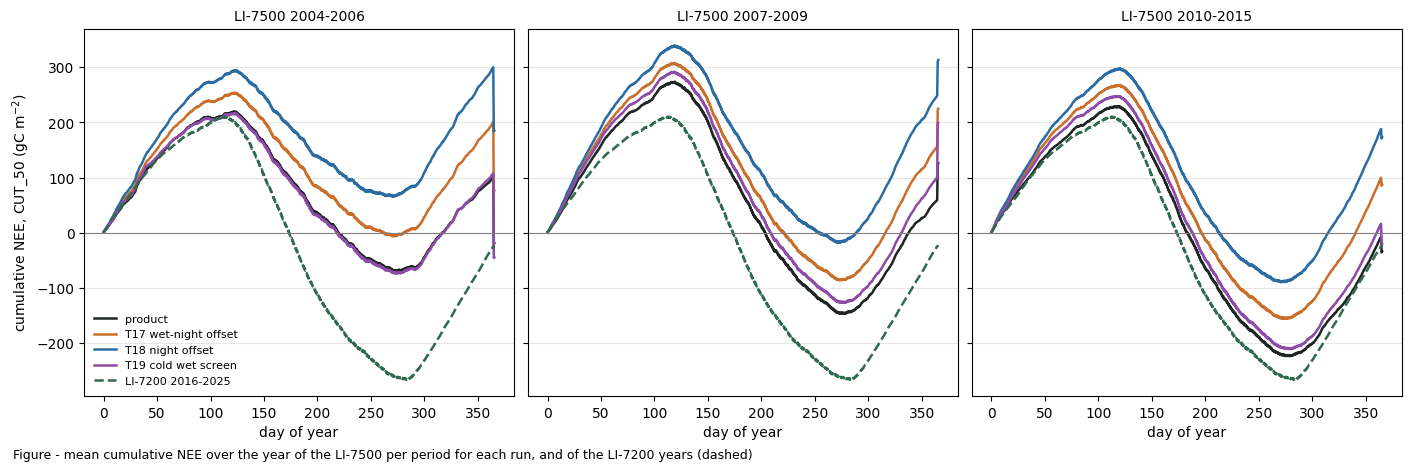

In [10]:
def cumulative(label, years):
    d = DATA[label]
    d = d.loc[d.index.year.isin(list(years)), 'CUT_50'] * UMOL_TO_GC
    c = d.groupby(d.index.year).cumsum()
    doy = np.floor(((d.index.dayofyear - 1) + d.index.hour / 24 + d.index.minute / 1440) * 2) / 2
    return c.groupby(doy).mean()


fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout='constrained', sharey=True)
_colors = {'product': '#1F2623', 'T17 wet-night offset': '#C96F2B', 'T18 night offset': '#2B6CA3', 'T19 cold wet screen': '#8E4BA8'}
_ref_c = cumulative('IRGA72 product', range(REF_YEARS[0], REF_YEARS[1] + 1))
for ax, p in zip(axes, ('2004-2006', '2007-2009', '2010-2015')):
    lo, hi = PERIODS[p]
    for l in TEST_RUNS:
        if l in DATA:
            c = cumulative(l, range(lo, hi + 1))
            ax.plot(c.index, c, lw=1.8, color=_colors[l], label=l)
    ax.plot(_ref_c.index, _ref_c, lw=1.8, color='#2E6A4E', ls='--', label=f'LI-7200 {REF_YEARS[0]}-{REF_YEARS[1]}')
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set_title(f'LI-7500 {p}', fontsize=10)
    ax.set_xlabel('day of year')
    ax.grid(axis='y', color='0.9')
axes[0].set_ylabel('cumulative NEE, CUT_50 (gC m$^{-2}$)')
axes[0].legend(frameon=False, fontsize=8)
figcap(fig, "mean cumulative NEE over the year of the LI-7500 per period for each run, and of the "
            "LI-7200 years (dashed)")
plt.show()

## ⏱️ Runtime

In [11]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-11 17:56:52, runtime 0:00:02.924595
